In [ ]:
from google.colab import userdata
userdata.get('KAGGLE_API_KEY')

'KGAT_0fe230439739a7f212446c2bc5467983'

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
train_df = pd.read_csv('/content/train.csv')
test_df = pd.read_csv('/content/test.csv')

In [ ]:
numerical_df = train_df.select_dtypes(include=['int64', 'float64']) #dropping non-numerical columns
len(numerical_df.columns)

38

In [ ]:
numerical_df.columns.tolist()

['Id',
 'MSSubClass',
 'LotFrontage',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageYrBlt',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold',
 'SalePrice']

In [ ]:
numerical_df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


### Part 1: Exploratory Data Analysis

In [ ]:
corr = numerical_df.corr()
salesprice_corr = corr['SalePrice'] #all features correlating with SalePrice
top5 = salesprice_corr.abs().sort_values(ascending=False)[1:6] #top 5 numerical feature with strong correlation with SalePrice
top5_feature = top5.index.tolist()
print(top5)

OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
GarageArea     0.623431
TotalBsmtSF    0.613581
Name: SalePrice, dtype: float64


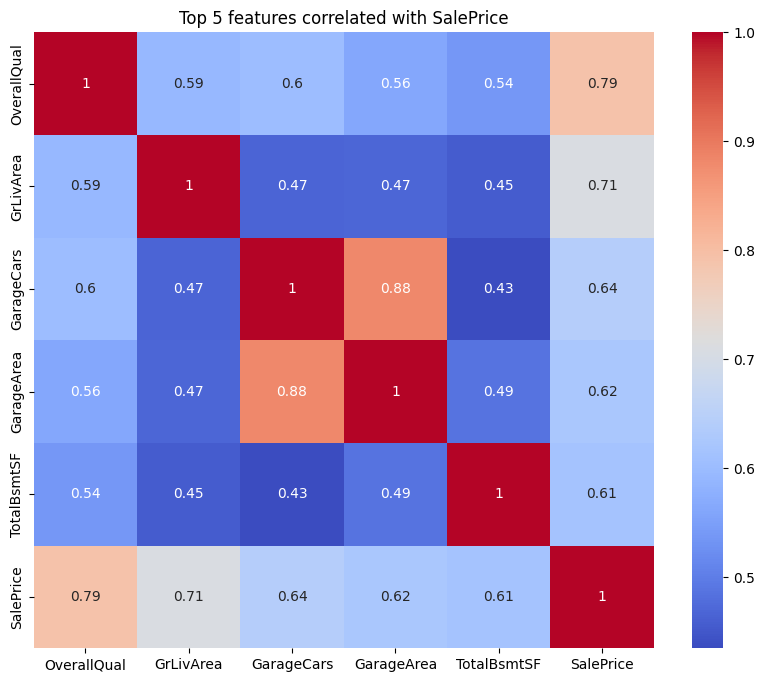

In [ ]:
heatmap_data = numerical_df[top5_feature + ['SalePrice']]
plt.figure(figsize=(10,8))
sns.heatmap(heatmap_data.corr(), annot=True, cmap='coolwarm')
plt.title('Top 5 features correlated with SalePrice')
plt.show()

In [ ]:
top3 = top5.index.tolist()[:3] # Top 3 features correlated to SalePrice
print(top3)

['OverallQual', 'GrLivArea', 'GarageCars']


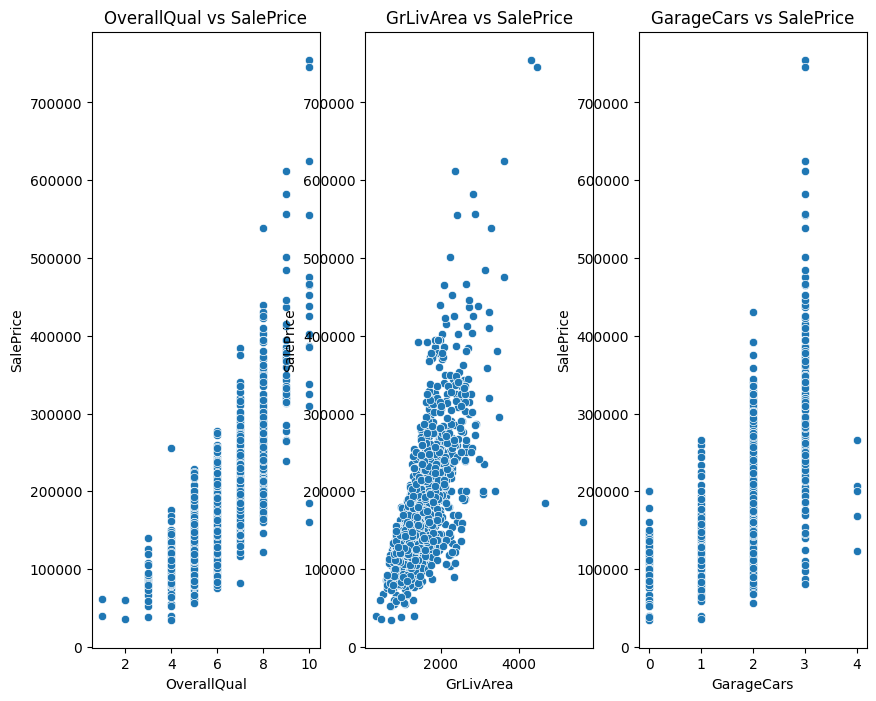

In [ ]:
plt.figure(figsize=(10,8))
for i,col in enumerate(top3):
  plt.subplot(1, 3, i + 1)
  sns.scatterplot(data= heatmap_data, x= col, y= 'SalePrice') # scatterplot for the top 3 features correlated with SalePrice
  plt.xlabel(col)
  plt.ylabel('SalePrice')
  plt.title(f'{col} vs SalePrice')
plt.show()

The patterns for each data are looking good. OverallQual shows that as quality increases SalePrice also increase meaning houses with better quality are more expensive. GrLivArea's dots form a diagonal line upward, it has a very strong correlation with Sale Price. GarageCars isn't as smooth as others.
All patterns has a positive relationship with SalePrice

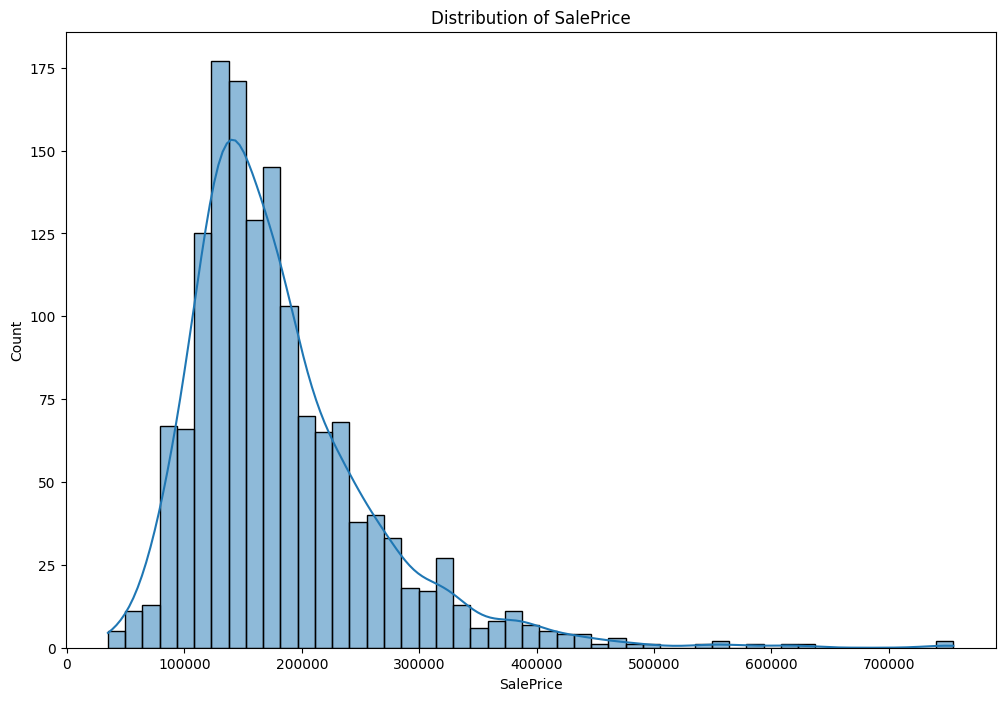

In [ ]:
plt.figure(figsize=(12,8))
sns.histplot(numerical_df['SalePrice'], kde=True)
plt.title(f'Distribution of SalePrice')
plt.show()

The histogram shows that SalesPrice is not normally distributed. It is right skewed. This indicates that houses with lower prices are sold the most, while those with higher prices are not really sold.

A skewed target variable can negatively affect linear regression because the model assumes normally distributed errors. As a result, the model may perform poorly, especially for higher-priced houses.

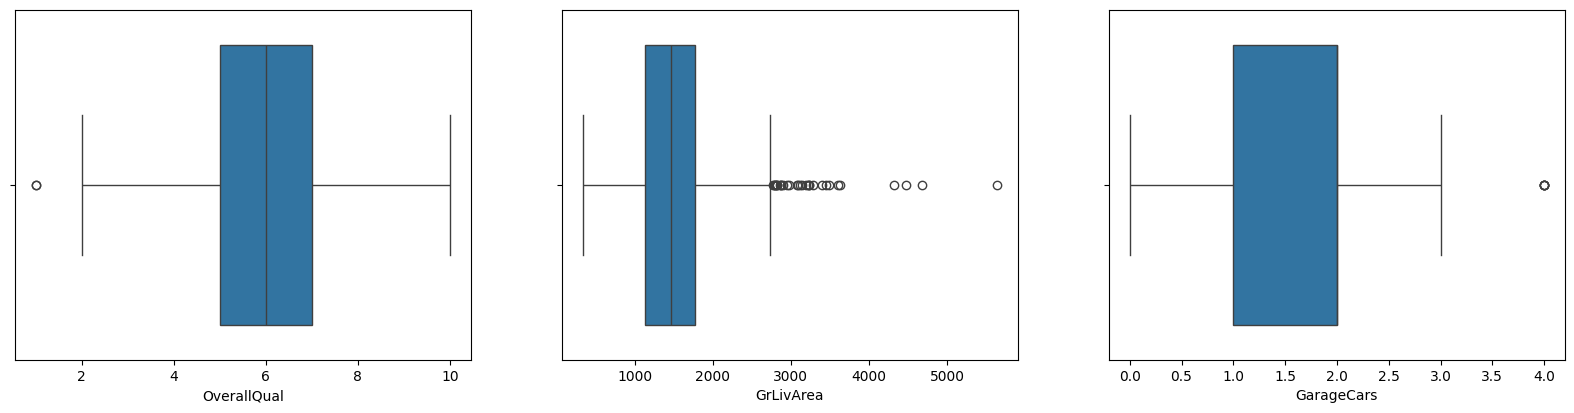

In [ ]:
top_features = ['OverallQual', 'GrLivArea', 'GarageCars']
plt.figure(figsize=(20,10))

for i,col in enumerate(top_features):
  plt.subplot(2, 3, i + 1)
  sns.boxplot(x=numerical_df[col])
plt.show()

In [ ]:
for col in top_features:
  Q1 = numerical_df[col].quantile(0.25)
  Q3 = numerical_df[col].quantile(0.75)
  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  outliers = numerical_df[(numerical_df[col] < lower_bound) | (numerical_df[col] > upper_bound)]

print(outliers)

        Id  MSSubClass  LotFrontage  LotArea  OverallQual  OverallCond  \
420    421          90         78.0     7060            7            5   
747    748          70         65.0    11700            7            7   
1190  1191         190          NaN    32463            4            4   
1340  1341          20         70.0     8294            4            5   
1350  1351          90         91.0    11643            5            5   

      YearBuilt  YearRemodAdd  MasVnrArea  BsmtFinSF1  ...  WoodDeckSF  \
420        1997          1998       200.0        1309  ...           0   
747        1880          2003         0.0           0  ...         181   
1190       1961          1975       149.0        1159  ...         439   
1340       1971          1971         0.0           0  ...           0   
1350       1969          1969       368.0         500  ...           0   

      OpenPorchSF  EnclosedPorch  3SsnPorch  ScreenPorch  PoolArea  MiscVal  \
420             0              

In [ ]:
outliers.count()

,0
Id,5
MSSubClass,5
LotFrontage,4
LotArea,5
OverallQual,5
OverallCond,5
YearBuilt,5
YearRemodAdd,5
MasVnrArea,5
BsmtFinSF1,5


In [ ]:
outliers

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
420,421,90,78.0,7060,7,5,1997,1998,200.0,1309,...,0,0,0,0,0,0,0,11,2008,206300
747,748,70,65.0,11700,7,7,1880,2003,0.0,0,...,181,0,386,0,0,0,0,5,2009,265979
1190,1191,190,NaN,32463,4,4,1961,1975,149.0,1159,...,439,0,0,0,0,0,0,3,2007,168000
1340,1341,20,70.0,8294,4,5,1971,1971,0.0,0,...,0,0,0,0,0,0,0,6,2007,123000
1350,1351,90,91.0,11643,5,5,1969,1969,368.0,500,...,0,0,0,0,0,0,0,8,2009,200000


Outliers were identified in the top features (OverallQual, GrLivArea, and GarageCars) using the IQR method.

GrLivArea showed some outliers representing very large houses. These values were kept because they are realistic and represent high-value properties.

GarageCars also had a few outliers, indicating houses with many garage spaces. These were kept since such houses exist in real life.

OverallQual did not have extreme invalid values because it is measured on a fixed scale, so its values were kept.

### Part 2: Data Cleaning

In [ ]:
numerical_df.isnull().sum()

,0
Id,0
MSSubClass,0
LotFrontage,259
LotArea,0
OverallQual,0
OverallCond,0
YearBuilt,0
YearRemodAdd,0
MasVnrArea,8
BsmtFinSF1,0


In [ ]:
numerical_df['LotFrontage'] = numerical_df['LotFrontage'].fillna(numerical_df['LotFrontage'].mean())
numerical_df['MasVnrArea'] = numerical_df['MasVnrArea'].fillna(0)
numerical_df['GarageYrBlt'] = numerical_df['GarageYrBlt'].fillna(0)
numerical_df.isnull().sum().sum()

np.int64(0)

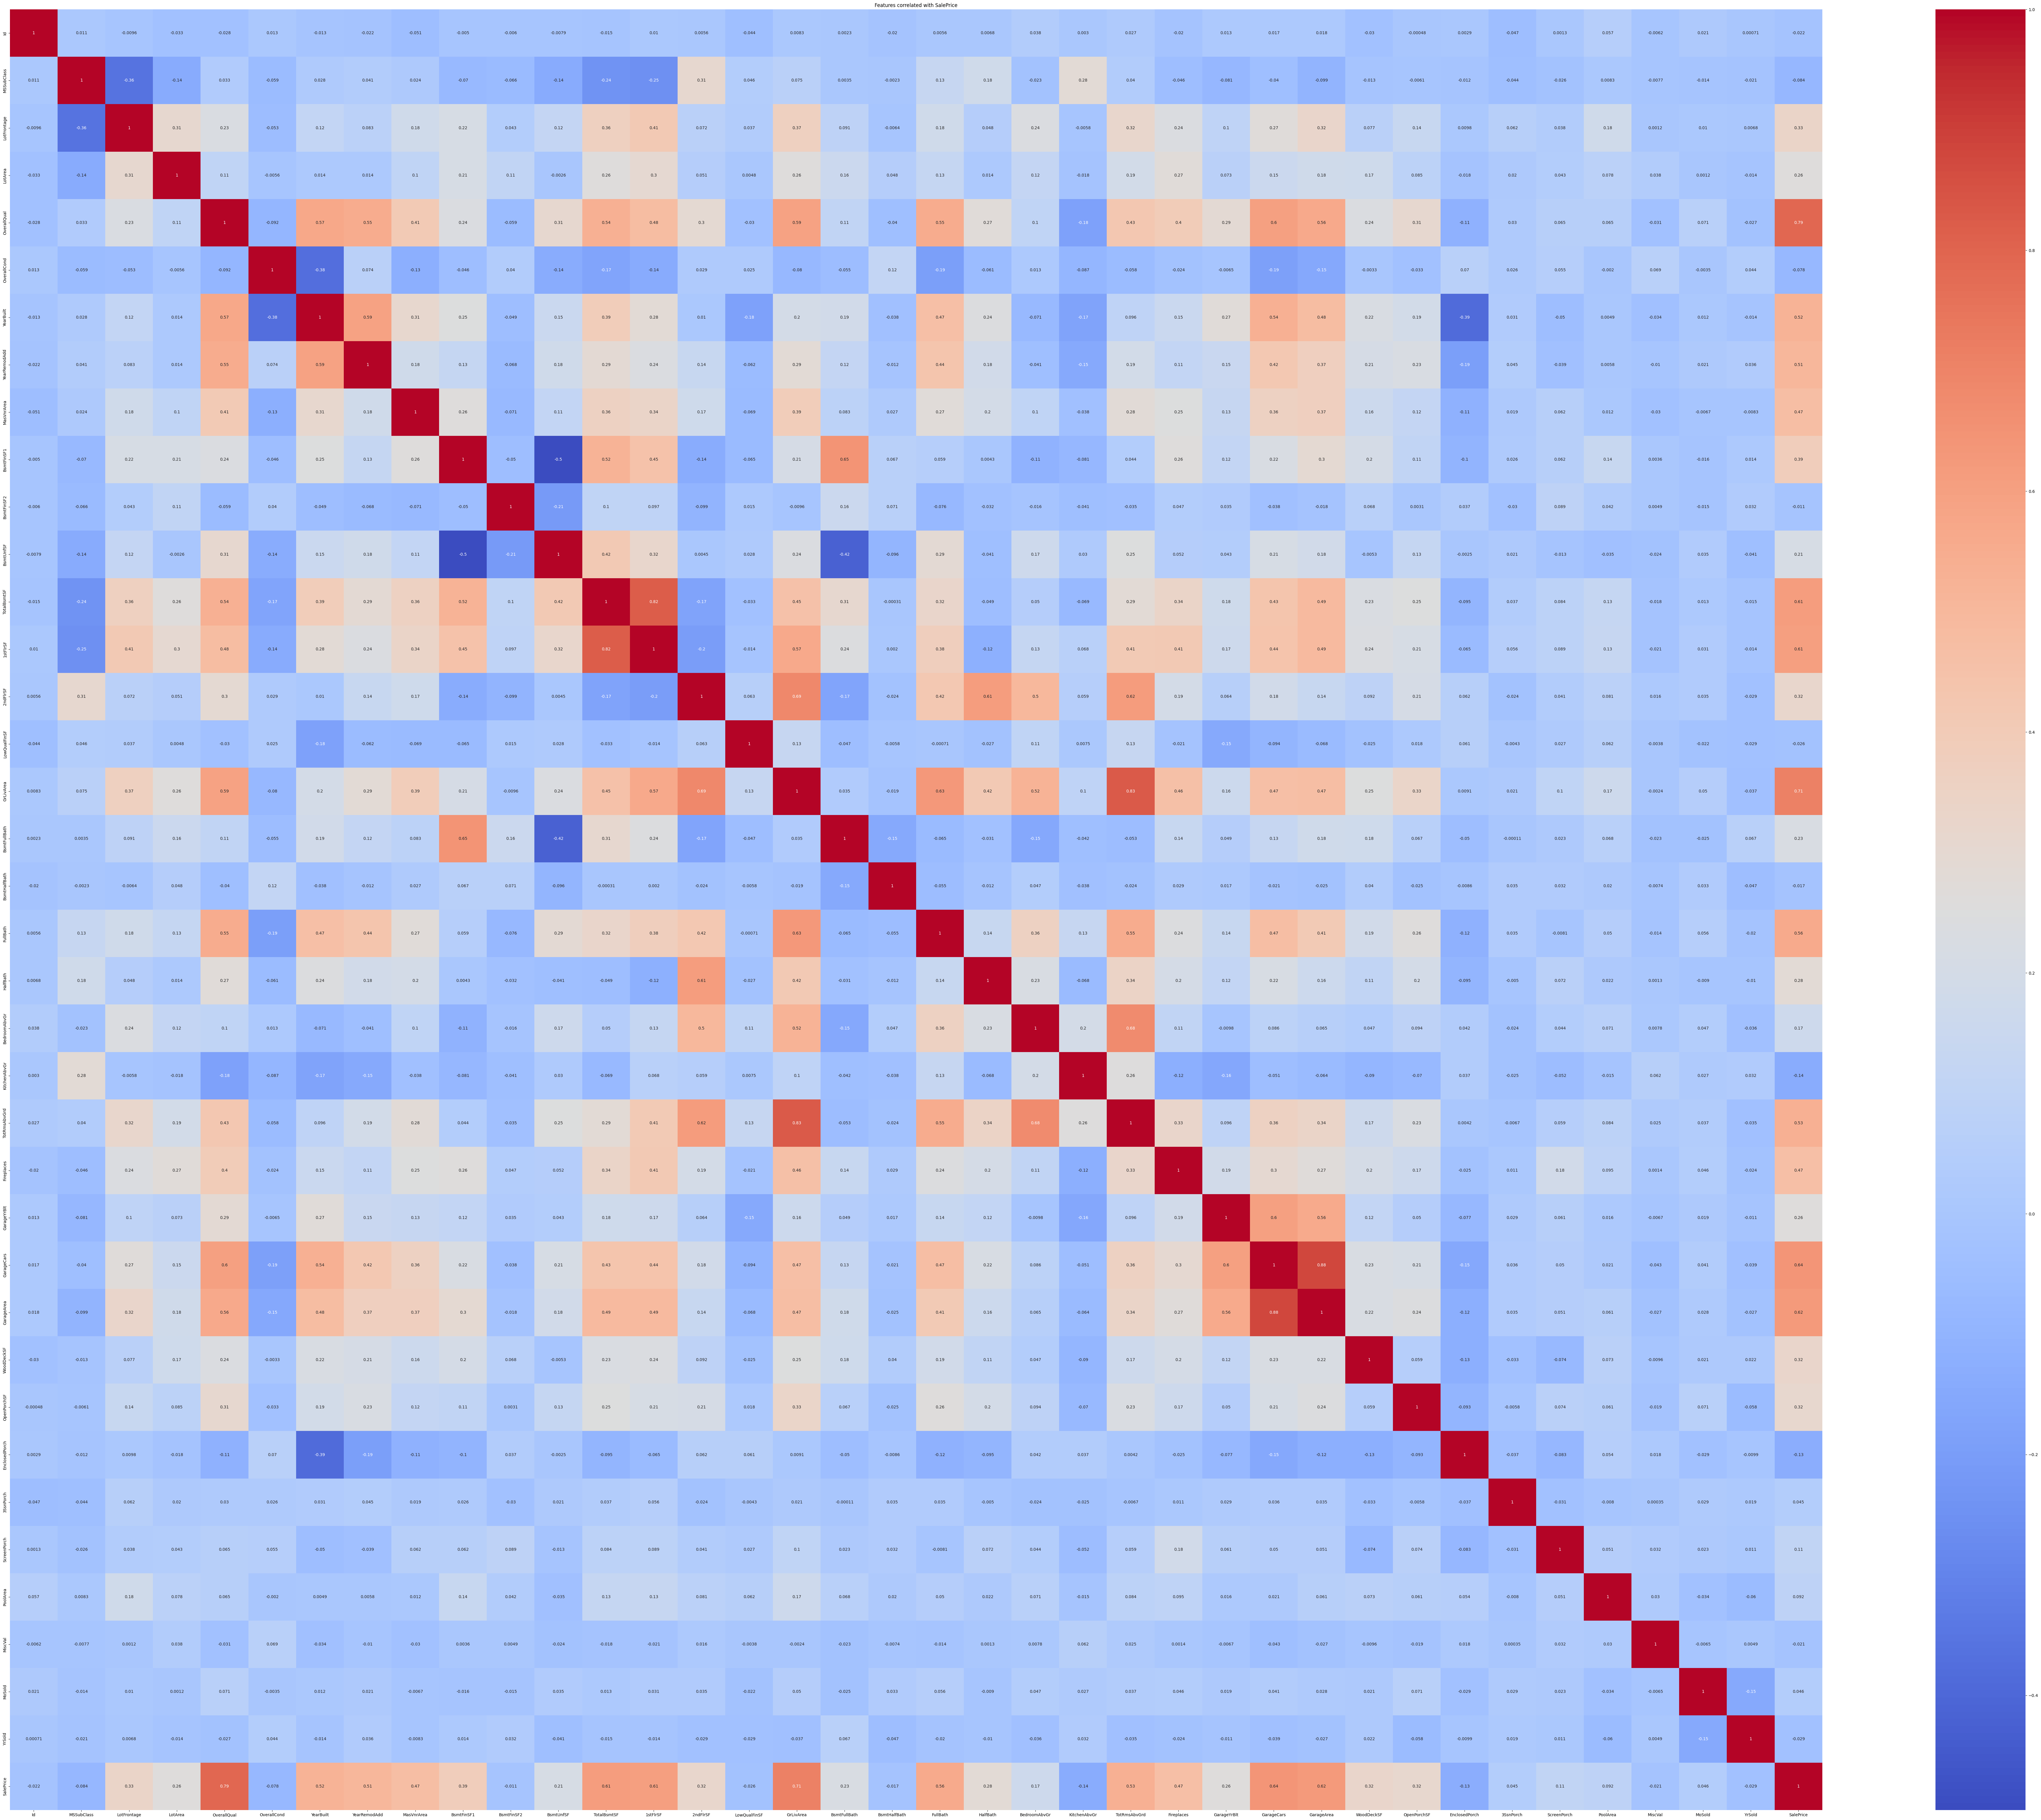

In [ ]:
plt.figure(figsize=(100,80))
sns.heatmap(numerical_df.corr(), annot=True, cmap='coolwarm')
plt.title('Features correlated with SalePrice')
plt.show()

In [ ]:
for col in corr.columns:
  for row in corr.index:
    if row != col and abs(corr.loc[row, col]) > 0.8:
      print(row, col, corr.loc[row, col])

GarageYrBlt YearBuilt 0.8256674841743408
1stFlrSF TotalBsmtSF 0.8195299750050339
TotalBsmtSF 1stFlrSF 0.8195299750050339
TotRmsAbvGrd GrLivArea 0.8254893743088425
GrLivArea TotRmsAbvGrd 0.8254893743088425
YearBuilt GarageYrBlt 0.8256674841743408
GarageArea GarageCars 0.882475414281462
GarageCars GarageArea 0.882475414281462


In [ ]:
numerical_df = numerical_df.drop(['1stFlrSF', 'GarageArea', 'TotalBsmtSF'], axis=1)

In [ ]:
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(numerical_df), columns=numerical_df.columns)
print(df_scaled[:10])

         Id  MSSubClass   LotFrontage   LotArea  OverallQual  OverallCond  \
0 -1.730865    0.073375 -2.293718e-01 -0.207142     0.651479    -0.517200   
1 -1.728492   -0.872563  4.519361e-01 -0.091886    -0.071836     2.179628   
2 -1.726120    0.073375 -9.311018e-02  0.073480     0.651479    -0.517200   
3 -1.723747    0.309859 -4.564744e-01 -0.096897     0.651479    -0.517200   
4 -1.721374    0.073375  6.336182e-01  0.375148     1.374795    -0.517200   
5 -1.719002   -0.163109  6.790387e-01  0.360616    -0.795151    -0.517200   
6 -1.716629   -0.872563  2.248335e-01 -0.043379     1.374795    -0.517200   
7 -1.714256    0.073375  6.454645e-16 -0.013513     0.651479     0.381743   
8 -1.711883   -0.163109 -8.652591e-01 -0.440659     0.651479    -0.517200   
9 -1.709511    3.147673 -9.106796e-01 -0.310370    -0.795151     0.381743   

   YearBuilt  YearRemodAdd  MasVnrArea  BsmtFinSF1  ...  WoodDeckSF  \
0   1.050994      0.878668    0.514104    0.575425  ...   -0.752176   
1   0.1567

Feature scaling makes all numerical variables have similar ranges. This helps linear regression treat all features equally. It is especially important for regularisation because this method penalize coefficients, and without scaling, some features may be unfairly penalized more than others.

PART 3: Feature Engineering

In [ ]:
numerical_df['YearsSinceRemod'] = numerical_df['YrSold'] - numerical_df['YearRemodAdd']
numerical_df['HouseAge'] = numerical_df['YrSold'] - numerical_df['YearBuilt']
numerical_df['TotalBathrooms'] = numerical_df['FullBath'] + 0.5 * numerical_df['HalfBath']

numerical_df['SalePrice_log'] = np.log(numerical_df['SalePrice'])

PART 4: Modeling

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X = numerical_df.drop(['SalePrice','SalePrice_log'], axis=1)
y = numerical_df['SalePrice_log']

model = LinearRegression()

scores = cross_val_score(model, X, y, cv=5, scoring='neg_root_mean_squared_error')

rmse_scores = -scores

print("RMSE for each fold:", rmse_scores)
print("AVERAGE RMSE:", rmse_scores.mean())

RMSE for each fold: [0.13456418 0.16268647 0.14311298 0.12907737 0.20276669]
AVERAGE RMSE: 0.15444153868106952
